# Part 1 · Notebook 1: Exploring EuroSAT

**Goal:** understand what separates the 10 land-cover classes before training any model, and turn it into
hypotheses for [notebook 2](02_eurosat_models.ipynb).

**Key findings**

- 27,000 tiles (64 × 64 pixels, 13 bands), 10 classes of 2,000 to 3,000 tiles. The official splits are
  alike and no cleaning is needed.
- Average colour separates SeaLake, Forest and Pasture. Six classes overlap: AnnualCrop, PermanentCrop,
  HerbaceousVegetation, Highway, Industrial and Residential.
- The overlapping classes differ mostly outside RGB (red edge, near-infrared, short-wave infrared), and some
  by their shapes rather than their colour.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from sentinel_agri.config import (
    BAND_RESOLUTION_M,
    BAND_WAVELENGTH_NM,
    BANDS_BY_WAVELENGTH,
    EUROSAT_BANDS,
    EUROSAT_CLASSES,
    FIGURES_DIR,
)
from sentinel_agri.data import eurosat, load_tile_features, to_rgb

sns.set_theme(style="whitegrid", context="notebook")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RNG = np.random.default_rng(42)

## 1. What is in one tile?

In [3]:
train_ds = eurosat("train")
sample = train_ds[0]
image, label = sample["image"], int(sample["label"])

print("Class:", train_ds.classes[label])
print("Shape (bands, height, width):", tuple(image.shape), "| dtype:", image.dtype)

pd.DataFrame(
    {
        "wavelength_nm": [BAND_WAVELENGTH_NM[b] for b in EUROSAT_BANDS],
        "native_resolution_m": [BAND_RESOLUTION_M[b] for b in EUROSAT_BANDS],
        "min": image.amin(dim=(1, 2)).numpy(),
        "mean": image.mean(dim=(1, 2)).numpy().round(),
        "max": image.amax(dim=(1, 2)).numpy(),
    },
    index=EUROSAT_BANDS,
)

Class: AnnualCrop
Shape (bands, height, width): (13, 64, 64) | dtype: torch.float32


,wavelength_nm,native_resolution_m,min,mean,max
B01,443,60,1235.0,1323.0,1420.0
B02,492,10,1002.0,1125.0,1534.0
B03,560,10,905.0,1045.0,1664.0
B04,665,10,893.0,1169.0,2297.0
B05,704,20,1034.0,1292.0,2128.0
B06,741,20,1120.0,1554.0,2376.0
B07,783,20,1238.0,1766.0,2689.0
B08,833,10,1186.0,1749.0,2977.0
B09,945,60,353.0,484.0,631.0
B10,1374,60,9.0,12.0,14.0


**What it shows**

- Values are reflectance × 10,000, measured at the top of the atmosphere (Level-1C), so they include haze.
- This AnnualCrop tile is bare soil (NDVI ≈ 0.20): EuroSAT shows fields at every stage.
- B09 and B10 are low because the atmosphere absorbs their light: they describe the air more than the ground.

## 2. Class balance and splits

Most of this notebook uses a table of per-tile statistics: mean and standard deviation of each band and of
NDVI.

In [4]:
features = load_tile_features()
print(features.shape)
features.head()

(27000, 32)


,mean_B01,mean_B02,mean_B03,mean_B04,mean_B05,mean_B06,mean_B07,mean_B08,mean_B09,mean_B10,...,std_B10,std_B11,std_B12,std_B8A,ndvi_mean,ndvi_std,label,class,split,path
0,1323.202637,1124.514648,1044.731934,1169.281494,1291.627197,1553.754883,1765.669434,1748.955322,484.055908,11.569824,...,0.992774,257.566040,257.616913,435.641937,0.188847,0.095455,0,AnnualCrop,train,/home/moha/agri_sentinel_ai/data/raw/eurosat/d...
1,1187.089844,1017.638428,1143.992188,1074.077637,1594.368896,3338.721436,4063.268555,3999.760742,1782.841797,16.655762,...,3.647959,1204.296631,1166.780151,984.981384,0.561320,0.280182,0,AnnualCrop,train,/home/moha/agri_sentinel_ai/data/raw/eurosat/d...
2,1613.533936,1543.559082,1612.584961,1922.695312,2114.679688,2631.855713,3002.193359,2893.610352,700.943604,15.130371,...,1.213315,590.388977,594.117615,438.883453,0.201834,0.165387,0,AnnualCrop,train,/home/moha/agri_sentinel_ai/data/raw/eurosat/d...
3,1546.874268,1442.861328,1532.079834,1649.649414,1966.929443,3062.829590,3540.499023,3381.061279,771.992432,14.589355,...,1.888420,905.692993,911.069092,606.642700,0.348173,0.242890,0,AnnualCrop,train,/home/moha/agri_sentinel_ai/data/raw/eurosat/d...
4,1508.039551,1290.349121,1242.706299,1258.629639,1502.869629,2493.611084,3081.958252,2964.619873,930.400879,14.439209,...,1.293816,595.240173,804.184570,691.720398,0.390693,0.234288,0,AnnualCrop,train,/home/moha/agri_sentinel_ai/data/raw/eurosat/d...


In [5]:
counts = pd.crosstab(features["class"], features["split"])[["train", "val", "test"]]
counts["total"] = counts.sum(axis=1)
counts["share_%"] = (100 * counts["total"] / counts["total"].sum()).round(1)
counts

split,train,val,test,total,share_%
class,,,,,
AnnualCrop,1791,613,596,3000,11.1
Forest,1787,605,608,3000,11.1
HerbaceousVegetation,1799,628,573,3000,11.1
Highway,1505,499,496,2500,9.3
Industrial,1492,507,501,2500,9.3
Pasture,1195,409,396,2000,7.4
PermanentCrop,1481,481,538,2500,9.3
Residential,1863,583,554,3000,11.1
River,1460,511,529,2500,9.3


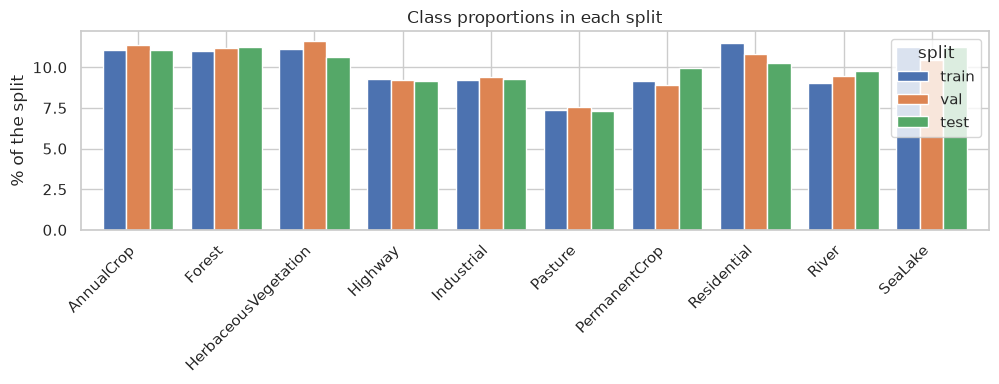

In [6]:
proportions = pd.crosstab(features["class"], features["split"], normalize="columns") * 100
ax = proportions[["train", "val", "test"]].plot.bar(figsize=(10, 4), width=0.8)
ax.set_ylabel("% of the split")
ax.set_xlabel("")
ax.set_title("Class proportions in each split")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "class_balance.png", dpi=150)

**What it shows**

- 2,000 (Pasture) to 3,000 tiles per class: a mild imbalance, so accuracy is meaningful; macro F1 is
  reported too.
- Class shares differ by at most 1.2 points between splits, so validation and test scores are comparable.

## 3. What the classes look like

Six random tiles per class, in true colour, then in false colour (near-infrared shown as red, so vegetation
appears red).

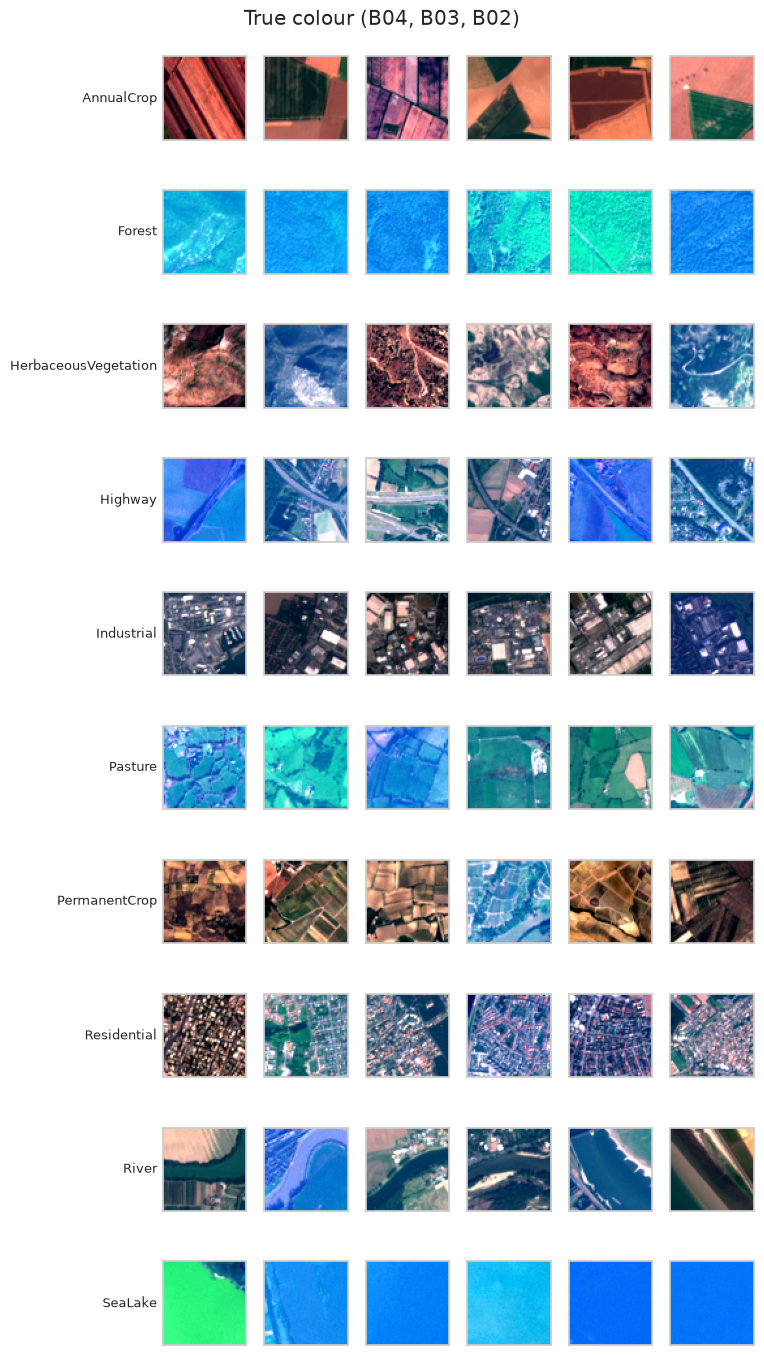

In [7]:
train = features[features.split == "train"].reset_index(drop=True)  # same row order as train_ds
N_PER_CLASS = 6
examples = {
    c: RNG.choice(train.index[train["class"] == c], N_PER_CLASS, replace=False) for c in EUROSAT_CLASSES
}


def show_grid(show, title, filename):
    fig, axes = plt.subplots(len(EUROSAT_CLASSES), N_PER_CLASS, figsize=(N_PER_CLASS * 1.3, 14))
    for row, (cls, indices) in enumerate(examples.items()):
        for col, idx in enumerate(indices):
            ax = axes[row, col]
            ax.imshow(to_rgb(train_ds[idx]["image"], show=show))
            ax.set_xticks([])
            ax.set_yticks([])
        axes[row, 0].set_ylabel(cls, rotation=0, ha="right", va="center", fontsize=9)
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / filename, dpi=120)


show_grid(("B04", "B03", "B02"), "True colour (B04, B03, B02)", "tiles_true_colour.png")

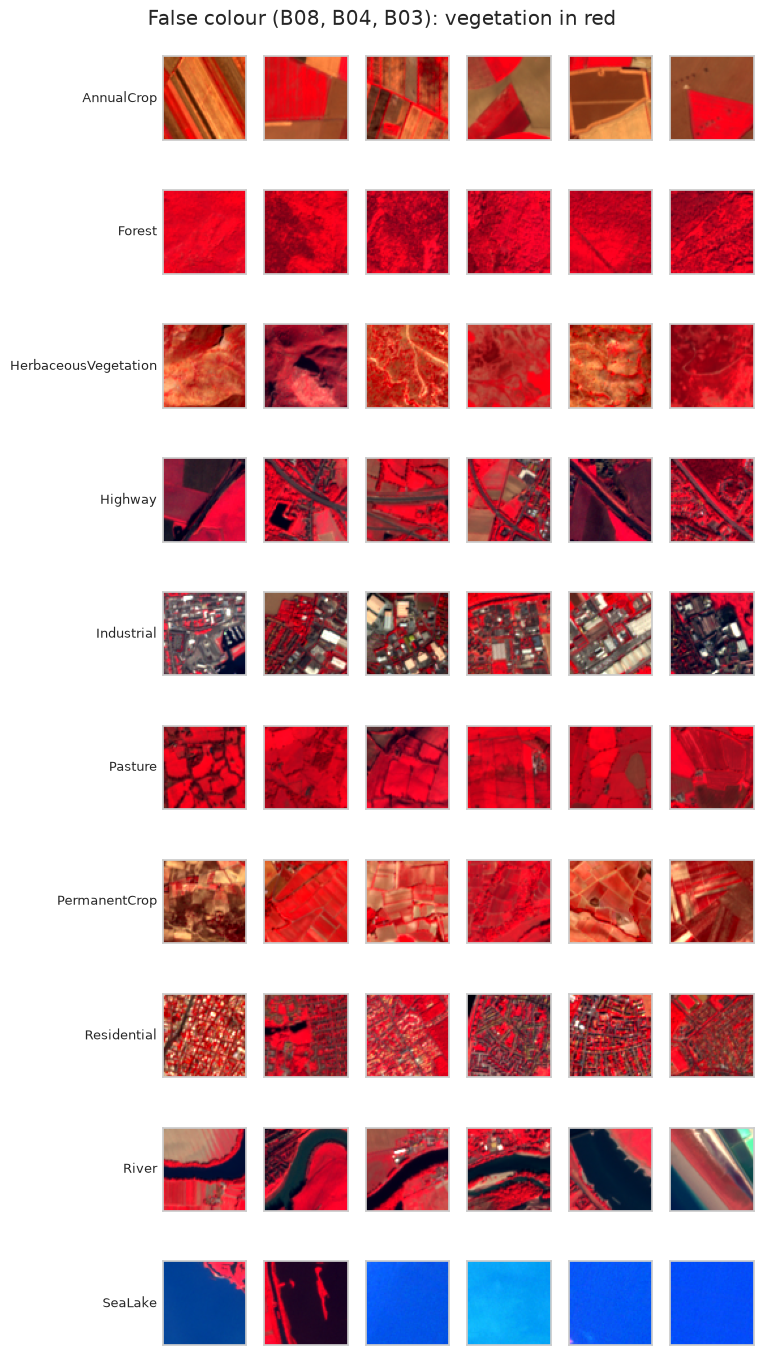

In [8]:
show_grid(("B08", "B04", "B03"), "False colour (B08, B04, B03): vegetation in red", "tiles_false_colour.png")

**What it shows**

- True colour looks blue because haze, still present in Level-1C data, scatters blue light. Only the pictures
  are affected.
- False colour separates vegetation (red), built-up areas (grey) and water (dark).
- Highway, Residential, Industrial and River are recognisable by their shapes. A label names what a tile
  contains, not what covers most of it: a Highway tile is mostly fields.

## 4. Data quality

In [9]:
mean_cols = [f"mean_{b}" for b in EUROSAT_BANDS]
std_cols = [f"std_{b}" for b in EUROSAT_BANDS]

print("Missing values:", int(features.isna().sum().sum()))
print("Tiles with a band mean of 0:", int((features[mean_cols] == 0).any(axis=1).sum()))
print("Tiles with a constant band (std = 0):", int((features[std_cols] == 0).any(axis=1).sum()))
print("Tiles with identical band means (possible duplicates):", int(features.duplicated(mean_cols).sum()))

features[mean_cols].describe().T.round(0)

Missing values: 0
Tiles with a band mean of 0: 0
Tiles with a constant band (std = 0): 3
Tiles with identical band means (possible duplicates): 0


,count,mean,std,min,25%,50%,75%,max
mean_B01,27000.0,1354.0,225.0,852.0,1183.0,1322.0,1481.0,2476.0
mean_B02,27000.0,1117.0,257.0,606.0,914.0,1086.0,1282.0,2507.0
mean_B03,27000.0,1042.0,310.0,400.0,838.0,1001.0,1227.0,2616.0
mean_B04,27000.0,947.0,478.0,228.0,569.0,861.0,1234.0,3280.0
mean_B05,27000.0,1199.0,491.0,192.0,877.0,1169.0,1477.0,3595.0
mean_B06,27000.0,2003.0,749.0,167.0,1690.0,2109.0,2487.0,4215.0
mean_B07,27000.0,2374.0,942.0,144.0,1978.0,2478.0,2972.0,5415.0
mean_B08,27000.0,2301.0,935.0,116.0,1904.0,2408.0,2898.0,5139.0
mean_B09,27000.0,732.0,382.0,46.0,500.0,716.0,936.0,2390.0
mean_B10,27000.0,12.0,4.0,4.0,9.0,11.0,14.0,156.0


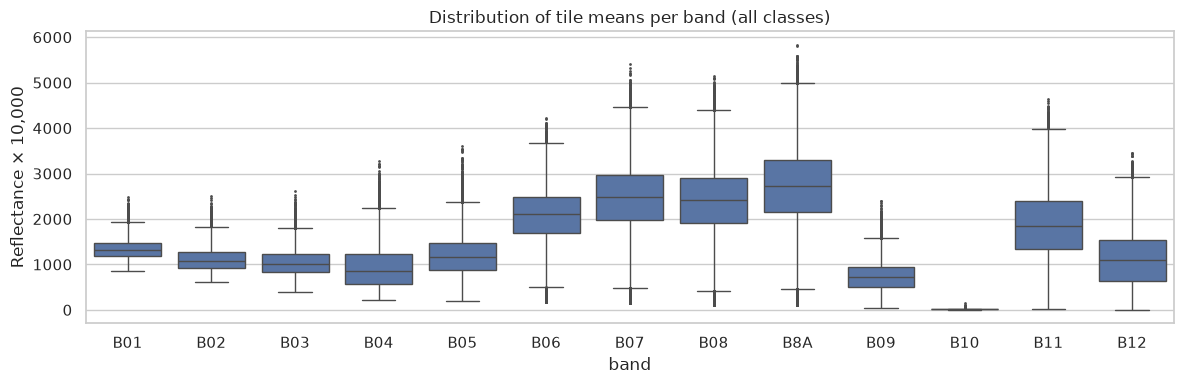

In [10]:
long = features.melt(id_vars="class", value_vars=mean_cols, var_name="band", value_name="tile_mean")
long["band"] = long["band"].str.removeprefix("mean_")
plt.figure(figsize=(12, 4))
sns.boxplot(data=long, x="band", y="tile_mean", order=BANDS_BY_WAVELENGTH, fliersize=1)
plt.title("Distribution of tile means per band (all classes)")
plt.ylabel("Reflectance × 10,000")
plt.tight_layout()

**What it shows**

- No missing values, empty tiles or duplicates: no cleaning.
- Band ranges differ about 200-fold (B10 ≈ 12, B8A ≈ 2,600), so the CNNs need per-band normalisation.
- 214 tiles show thin clouds in B10. They are kept: real images contain clouds too.

## 5. Spectral signatures

Average reflectance of each class in each band. Where the shaded areas (±1 standard deviation) overlap,
average colour cannot tell classes apart.

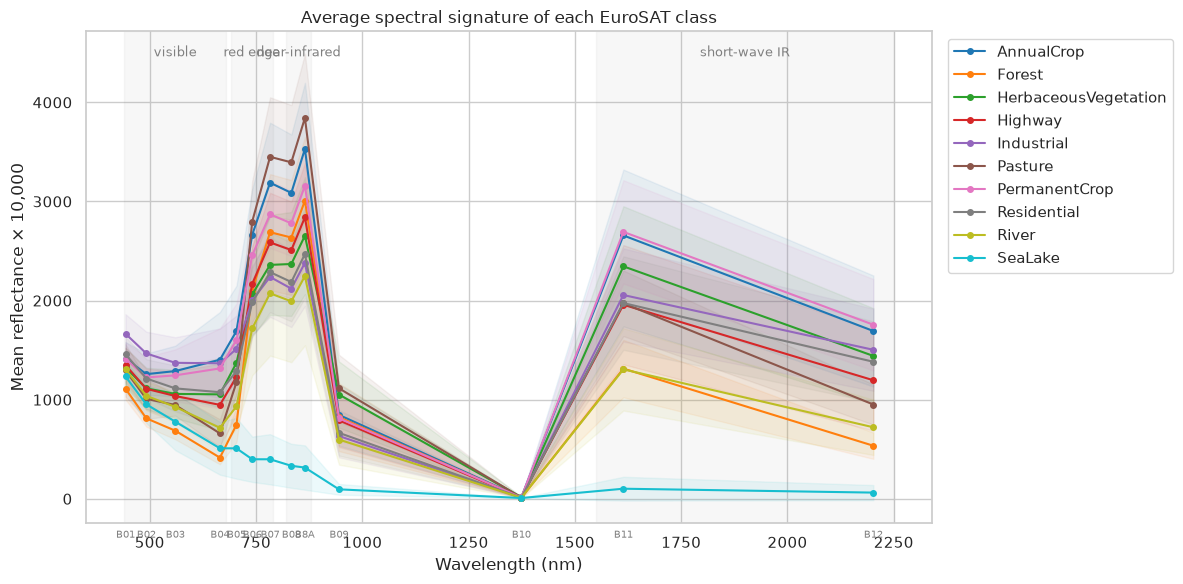

In [11]:
wavelengths = [BAND_WAVELENGTH_NM[b] for b in BANDS_BY_WAVELENGTH]
by_class = features.groupby("class")[[f"mean_{b}" for b in BANDS_BY_WAVELENGTH]]
mean_sig, std_sig = by_class.mean(), by_class.std()

fig, ax = plt.subplots(figsize=(12, 6.5))
palette = sns.color_palette("tab10", len(EUROSAT_CLASSES))
for cls, color in zip(EUROSAT_CLASSES, palette):
    m, s = mean_sig.loc[cls].to_numpy(), std_sig.loc[cls].to_numpy()
    ax.plot(wavelengths, m, marker="o", markersize=4, label=cls, color=color)
    ax.fill_between(wavelengths, m - s, m + s, color=color, alpha=0.08)

# Spectral regions; the labels alternate in height so that neighbouring ones do not overlap.
regions = [(440, 680, "visible", 0.97), (690, 790, "red edge", 0.91), (820, 880, "near-infrared", 0.97), (1550, 2250, "short-wave infrared", 0.97)]
for start, end, name, y in regions:
    ax.axvspan(start, end, color="grey", alpha=0.06)
    ax.text((start + end) / 2, y, name, ha="center", va="top", fontsize=9, color="grey", transform=ax.get_xaxis_transform())

# Band names on a top axis, rotated so that close bands (B05 to B8A) stay readable.
top = ax.secondary_xaxis("top")
top.set_xticks(wavelengths, labels=BANDS_BY_WAVELENGTH, rotation=90, fontsize=8)

ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Mean reflectance × 10,000")
ax.set_title("Average spectral signature of each EuroSAT class", pad=12)
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "spectral_signatures.png", dpi=150)

**What it shows**

- Three families: water (low everywhere), vegetation (low red, steep rise into the near-infrared), built-up
  (flat, bright in the visible).
- AnnualCrop and PermanentCrop have almost the same curve; they differ most in the near-infrared (B8A: 3,531
  against 3,159). HerbaceousVegetation, Highway and Residential also overlap.
- Where classes overlap, they differ mostly outside RGB, which leads to H4.

## 6. NDVI per class

NDVI = (B08 − B04) / (B08 + B04) sums up the vegetation signal in one number.

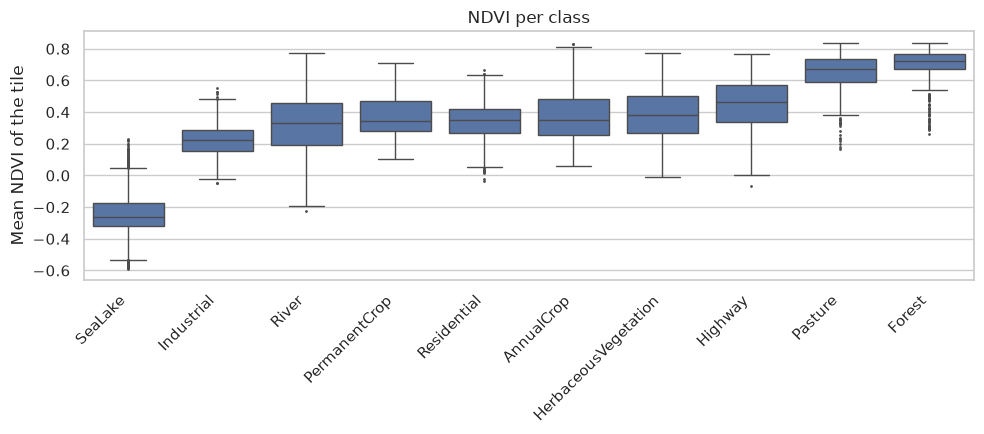

In [12]:
order = features.groupby("class")["ndvi_mean"].median().sort_values().index
plt.figure(figsize=(10, 4.5))
sns.boxplot(data=features, x="class", y="ndvi_mean", order=order, fliersize=1)
plt.xticks(rotation=45, ha="right")
plt.xlabel("")
plt.ylabel("Mean NDVI of the tile")
plt.title("NDVI per class")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "ndvi_per_class.png", dpi=150)

**What it shows**

- NDVI separates water (negative), built-up areas (low) and Forest or Pasture (high).
- Five classes share a median between 0.33 and 0.38, so NDVI alone cannot separate them.
- AnnualCrop spans 0.06 to 0.83: fields at every stage, from bare soil to full canopy.

## 7. Can average colour separate the classes?

The 13 band means of each tile, projected on their main axes of variation (PCA), in 2D, then in 3D from four
angles.

Variance explained by the 2 components: [0.613 0.254]


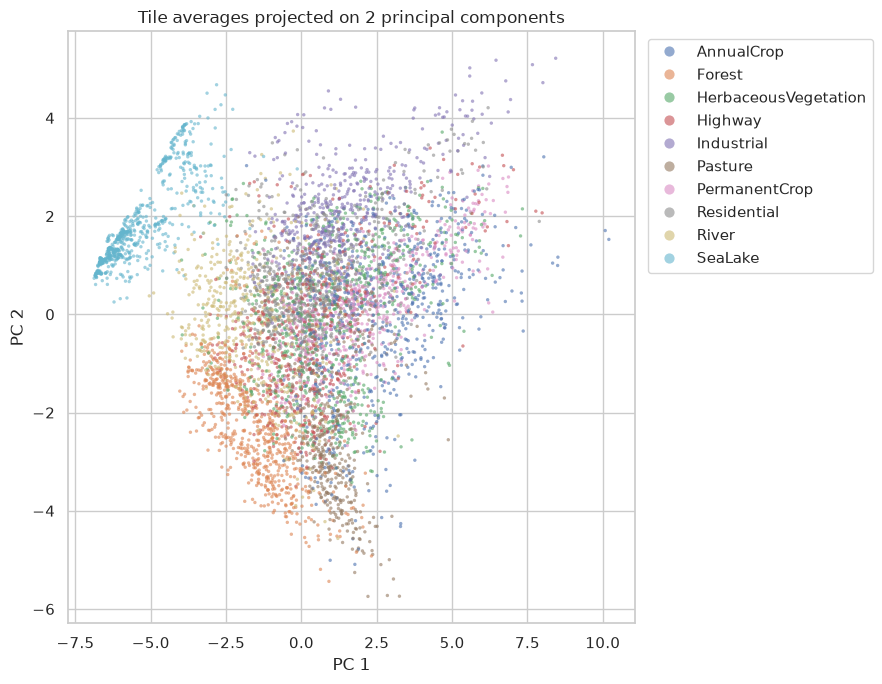

In [13]:
subset = features[features.split == "train"].sample(6000, random_state=42)
X = StandardScaler().fit_transform(subset[mean_cols])
pca = PCA(n_components=2).fit(X)
pcs = pca.transform(X)
print("Variance explained by the 2 components:", pca.explained_variance_ratio_.round(3))

plt.figure(figsize=(9, 7))
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=subset["class"], hue_order=EUROSAT_CLASSES, s=6, alpha=0.6, linewidth=0)
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.title("Tile averages projected on 2 principal components")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left", markerscale=3)
plt.tight_layout()

Variance explained by the 3 components: [0.613 0.254 0.066] | total: 0.933
Tiles outside the zoomed axes (not drawn): 174 of 6000


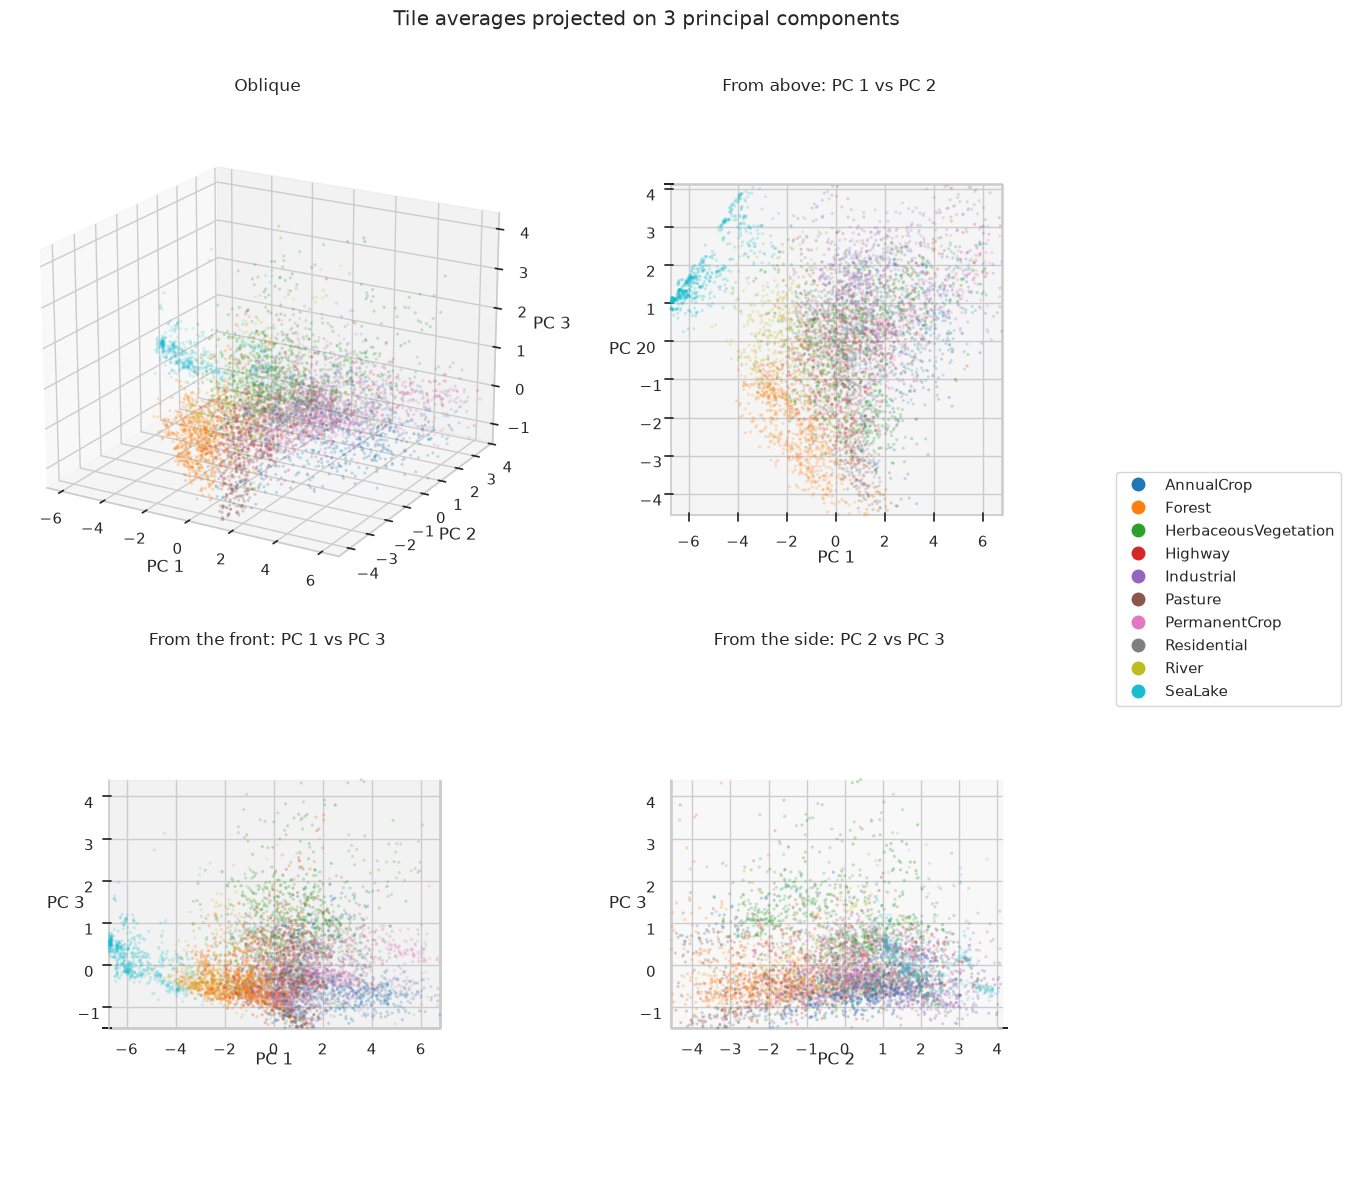

In [14]:
pca3 = PCA(n_components=3).fit(X)
pcs3 = pca3.transform(X)
explained = pca3.explained_variance_ratio_
print("Variance explained by the 3 components:", explained.round(3), "| total:", explained.sum().round(3))

# A few outlier tiles stretch the axes and squash everything else: zoom on the central 99 %.
low, high = np.percentile(pcs3, [0.5, 99.5], axis=0)
inside = ((pcs3 >= low) & (pcs3 <= high)).all(axis=1)
print(f"Tiles outside the zoomed axes (not drawn): {(~inside).sum()} of {len(pcs3)}")

palette = dict(zip(EUROSAT_CLASSES, sns.color_palette("tab10", len(EUROSAT_CLASSES))))
colors = subset["class"].map(palette).to_numpy()[inside]
views = [  # (elevation, azimuth, title, axis pointing at the viewer: 0 = PC 1, 1 = PC 2, 2 = PC 3)
    (20, -60, "Oblique", None),
    (90, -90, "From above: PC 1 vs PC 2", 2),
    (0, -90, "From the front: PC 1 vs PC 3", 1),
    (0, 0, "From the side: PC 2 vs PC 3", 0),
]

fig = plt.figure(figsize=(14, 12))
for k, (elev, azim, title, hidden) in enumerate(views, start=1):
    ax = fig.add_subplot(2, 2, k, projection="3d")
    ax.scatter(*pcs3[inside].T, c=colors, s=5, alpha=0.6, linewidths=0)
    ax.view_init(elev=elev, azim=azim)
    for d, axis in enumerate("xyz"):
        getattr(ax, f"set_{axis}lim")(low[d], high[d])
        getattr(ax, f"set_{axis}label")("" if d == hidden else f"PC {d + 1}")
        if d == hidden:  # its tick labels would be squashed into one point
            getattr(ax, f"set_{axis}ticklabels")([])
    if hidden is not None:
        ax.set_proj_type("ortho")  # no perspective: a flat view, like a 2D plot
    ax.set_title(title)

handles = [plt.Line2D([], [], marker="o", linestyle="", color=palette[c], label=c) for c in EUROSAT_CLASSES]
fig.legend(handles=handles, loc="center right", markerscale=1.5)
fig.suptitle("Tile averages projected on 3 principal components")
plt.tight_layout(rect=(0, 0, 0.86, 0.97))
plt.savefig(FIGURES_DIR / "pca_3d.png", dpi=130)

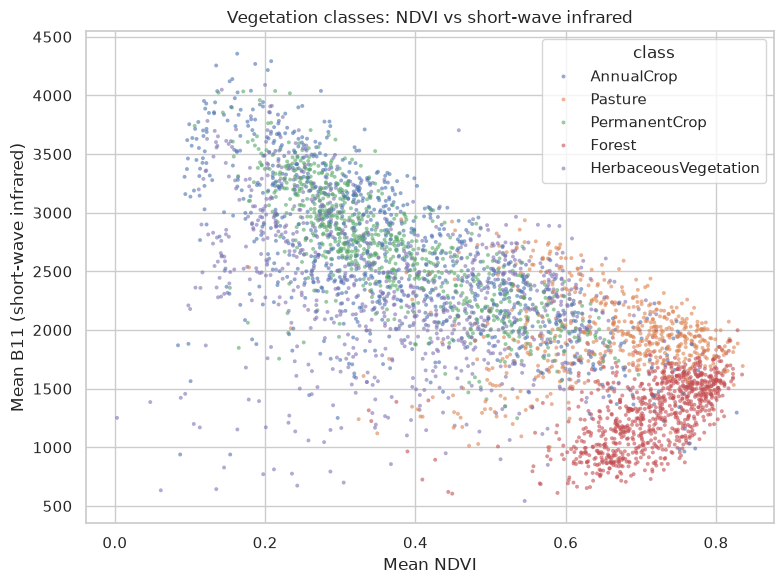

In [15]:
vegetation = ["AnnualCrop", "HerbaceousVegetation", "Pasture", "PermanentCrop", "Forest"]
veg = features[(features.split == "train") & features["class"].isin(vegetation)]
plt.figure(figsize=(8, 6))
sns.scatterplot(data=veg.sample(4000, random_state=0), x="ndvi_mean", y="mean_B11", hue="class", s=8, alpha=0.6, linewidth=0)
plt.xlabel("Mean NDVI")
plt.ylabel("Mean B11 (short-wave infrared)")
plt.title("Vegetation classes: NDVI vs short-wave infrared")
plt.tight_layout()

**What it shows**

- SeaLake, Forest and Pasture form their own groups; the six other classes mix in the centre.
- The third axis adds little: it is almost only B10 and B09, that is haze, not land cover.
- Short-wave infrared separates Forest from Pasture where their NDVI is similar (B11: 1,342 against 1,952).
- Expectation for a model that sees averages only: good on SeaLake, Forest and Pasture, weak on the other six
  (H1).

## 8. Is there information inside the tile?

Averages ignore the spatial pattern. The within-tile standard deviation is a rough measure of texture.

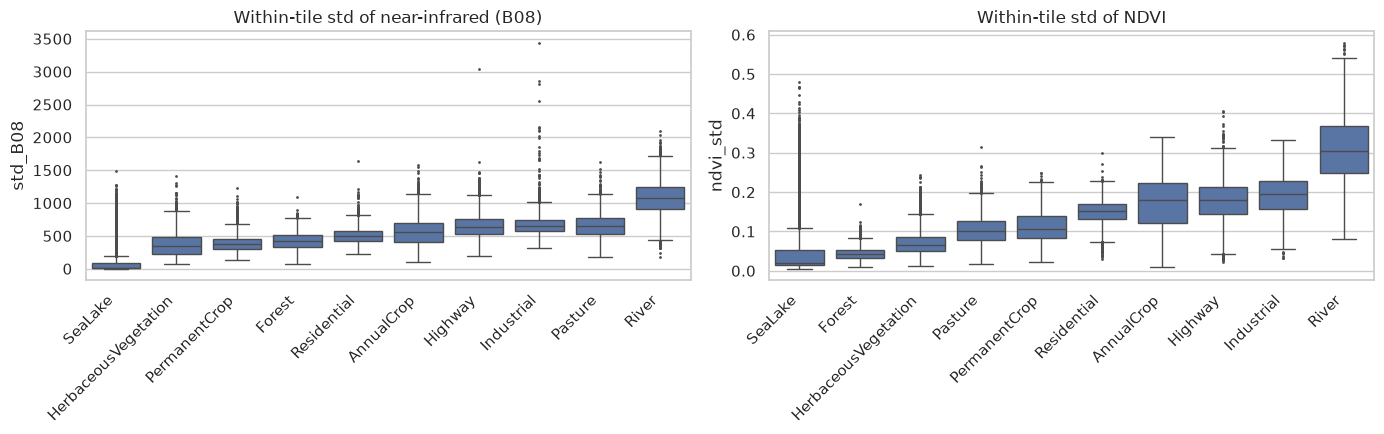

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, col, title in [
    (axes[0], "std_B08", "Within-tile std of near-infrared (B08)"),
    (axes[1], "ndvi_std", "Within-tile std of NDVI"),
]:
    order = features.groupby("class")[col].median().sort_values().index
    sns.boxplot(data=features, x="class", y=col, order=order, fliersize=1, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
    for label in ax.get_xticklabels():
        label.set_ha("right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "within_tile_variability.png", dpi=150)

**What it shows**

- River, Industrial, Highway, AnnualCrop and Residential vary most inside a tile: the classes recognised by
  their shapes in section 3.
- HerbaceousVegetation and PermanentCrop share their NDVI with AnnualCrop but are far more uniform. Models
  that see the pixels should gain on these classes (H2).

## 9. Band redundancy

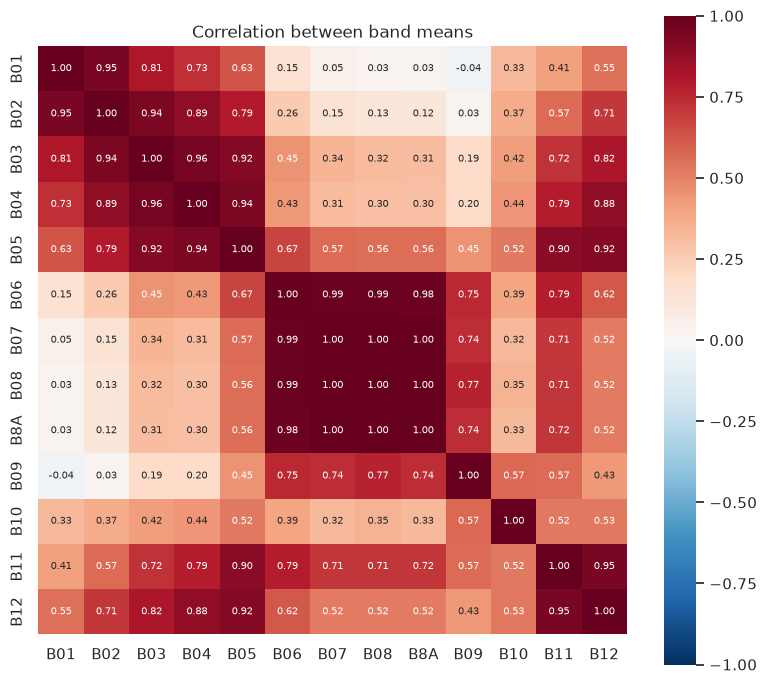

In [17]:
corr = features[[f"mean_{b}" for b in BANDS_BY_WAVELENGTH]].corr()
corr.index = corr.columns = BANDS_BY_WAVELENGTH
plt.figure(figsize=(8, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, annot_kws={"size": 7}, square=True)
plt.title("Correlation between band means")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "band_correlation.png", dpi=150)

**What it shows**

- The 13 bands form about five groups: visible, red edge and near-infrared (correlation ≥ 0.98),
  short-wave infrared, B09, B10.
- RGB correlates weakly with the near-infrared (0.13 to 0.32 with B08), so the extra bands carry
  information RGB lacks (H4).

## 10. Do the splits look alike?

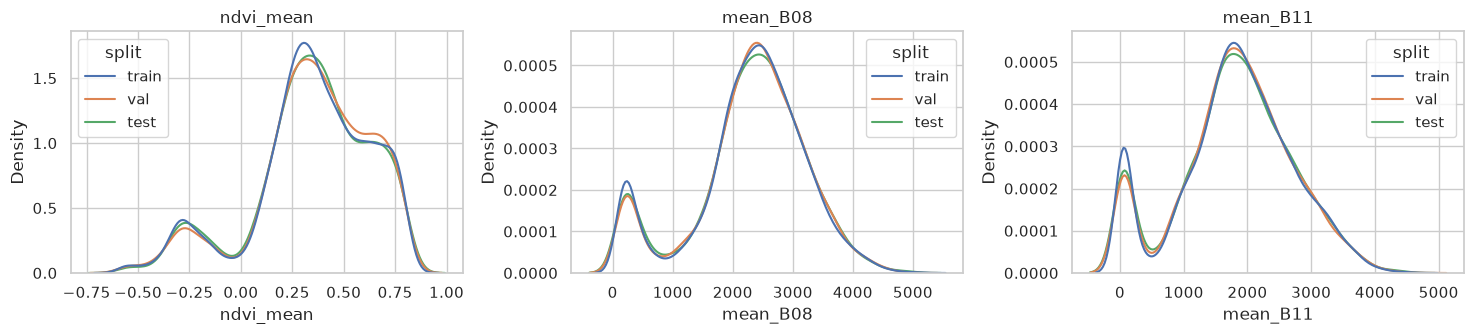

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col in zip(axes, ["ndvi_mean", "mean_B08", "mean_B11"]):
    sns.kdeplot(data=features, x=col, hue="split", common_norm=False, ax=ax)
    ax.set_title(col)
plt.tight_layout()

**What it shows**

- Train, validation and test have the same value distributions (Kolmogorov–Smirnov statistic ≤ 0.012),
  so validation scores should predict test scores.

## 11. Findings and their consequences

| Finding | Consequence for the models |
|---|---|
| Mild class imbalance; the three splits match | Report accuracy and macro F1; validation predicts test |
| Average colour separates 3 classes; 6 overlap | A model on averages should fail mostly on these 6 |
| Overlapping classes differ mostly outside RGB | 13 bands should beat RGB |
| Some classes are defined by their shapes | Models that see pixels should beat averages on them |
| Band ranges differ about 200-fold | Per-band normalisation |

**Limits of this analysis.** EuroSAT labels are taken as correct, tiles were selected to contain mostly one
class, and all data is Level-1C, with haze. [Notebook 3](03_eurosat_real_world.ipynb) shows how far real
images differ.

## 12. Hypotheses for notebook 2

Written before training, with what would refute them, so that the results cannot be read to fit any story.

| ID | Hypothesis | Tested by | Refuted if | Guess before training |
|---|---|---|---|---|
| H1 | Tile averages already separate most classes. | Random Forest on averages | Far below the CNNs on every class | 80–90 % |
| H2 | Texture matters most for Highway, Industrial, Residential, River, AnnualCrop. | Per-class gains of CNN over Random Forest | Gains spread evenly | Largest gain on Highway |
| H3 | Pretraining on Sentinel-2 helps. | Pretrained ResNet vs small CNN, 13 bands | Gain within noise (≈ 0.5 %) | +1 to 2 points |
| H4 | The extra bands help, mostly on vegetation. | Same small CNN on 13 bands vs RGB | No gain, or not on vegetation | +1 to 3 points |
| H5 | Remaining errors concentrate on agricultural classes. | Confusion matrix of the best model | Most errors elsewhere | AnnualCrop–PermanentCrop most confused |

Results: [notebook 2](02_eurosat_models.ipynb), section 7.